# 02 - Modelado: predicción del Happiness Score

Notebook de selección de características, entrenamiento, validación y evaluación de modelos de regresión sobre el dataset limpio del notebook `01_eda.ipynb`. Continúa el embudo de datos con las etapas de partición y evaluación.

## Objetivo
Predecir `score` (Happiness Score) a partir de variables socioeconómicas, con un procedimiento que evite fuga de información desde el conjunto de prueba.

## Entradas y salidas
| Tipo | Ruta | Descripción |
|---|---|---|
| Entrada | `data/clean_records.csv` | Dataset limpio (782 filas esperadas) |
| Entrada | `reports/tables/embudo_eda.csv` | Embudo de las etapas previas (opcional) |
| Salida | `models/model.joblib` | Pipeline entrenado y metadatos para el consumidor de streaming |
| Salida | `models/metrics.json` | Métricas del modelo seleccionado |
| Salida | `reports/figures/07_*.png` a `13_*.png` | Gráficas de partición, comparación y desempeño |
| Salida | `reports/tables/*.csv` | Comparación de modelos, predicciones de prueba y embudo completo |

## Etapas
1. Carga y validación del dataset limpio.
2. Definición de variable objetivo y predictoras.
3. Partición por país en entrenamiento y prueba.
4. Selección de características (ablación) con validación cruzada por grupos.
5. Preprocesamiento sin fuga de información.
6. Comparación de modelos con validación cruzada por grupos.
7. Evaluación en el conjunto de prueba: MAE, MSE, RMSE, R2 y R2 ajustado.
8. Diagnóstico: residuos, error por grupo e importancia de variables.
9. Persistencia del modelo y embudo completo.
10. Discusión y mejoras.

In [1]:
import os
import json
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
RUTA_CLEAN = "../data/clean_records.csv"
DIR_FIG = "../reports/figures"
DIR_TAB = "../reports/tables"
DIR_MOD = "../models"
for d in (DIR_FIG, DIR_TAB, DIR_MOD):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "black",
    "axes.grid": True, "grid.color": "0.85", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 9,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


## 1. Carga y validación del dataset limpio

Se carga la salida del EDA y se verifican sus invariantes antes de modelar. El embudo de etapas previas se importa desde `embudo_eda.csv` para continuarlo en este notebook; si el archivo no existe, el embudo empieza en el dataset limpio.

In [2]:
df = pd.read_csv(RUTA_CLEAN)
df["region"] = df["region"].astype(object)   # tipo compatible con scikit-learn

# Embudo: se continúa el generado en el EDA
ruta_embudo = f"{DIR_TAB}/embudo_eda.csv"
if os.path.exists(ruta_embudo):
    embudo = pd.read_csv(ruta_embudo).to_dict("records")
    print("Embudo previo cargado:", len(embudo), "etapas")
else:
    embudo = []
    print("Sin embudo previo: se inicia en el dataset limpio")

def registrar(etapa, filas, columnas=None, paises=None, nota=""):
    embudo.append({"etapa": etapa, "filas": filas, "columnas": columnas,
                   "paises_unicos": paises, "nota": nota})

esperadas = ["year", "country", "region", "rank", "score", "gdp", "social_support",
             "life_expectancy", "freedom", "corruption", "generosity"]
assert list(df.columns) == esperadas, "Columnas inesperadas en clean_records.csv"
assert not df.duplicated(["year", "country"]).any()
assert df["score"].notna().all()

print("Forma:", df.shape)
print("Países:", df["country"].nunique(), "| Años:", [int(y) for y in sorted(df["year"].unique())])
print("Nulos por columna:", df.isna().sum()[df.isna().sum() > 0].to_dict())
display(df.head())

Embudo previo cargado: 10 etapas
Forma: (782, 11)
Países: 164 | Años: [2015, 2016, 2017, 2018, 2019]
Nulos por columna: {'corruption': 1}


,year,country,region,rank,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
0,2015,Norway,Western Europe,4.0,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699
1,2015,Finland,Western Europe,6.0,7.406,1.29025,1.31826,0.88911,0.64169,0.41372,0.23351
2,2015,Sweden,Western Europe,8.0,7.364,1.33171,1.28907,0.91087,0.65980,0.43844,0.36262
3,2015,New Zealand,Australia and New Zealand,9.0,7.286,1.25018,1.31967,0.90837,0.63938,0.42922,0.47501
4,2015,Costa Rica,Latin America and Caribbean,12.0,7.226,0.95578,1.23788,0.86027,0.63376,0.10583,0.25497


## 2. Variable objetivo y predictoras

| Variable | Rol | Justificación |
|---|---|---|
| `score` | Objetivo | Happiness Score |
| `gdp`, `social_support`, `life_expectancy`, `freedom`, `corruption`, `generosity` | Predictoras numéricas | Presentes en los cinco años tras el mapa de nombres |
| `region` | Predictora categórica | Captura diferencias estructurales entre regiones |
| `year` | Predictora categórica | Varias predictoras cambian de nivel entre años (ver 01_eda, sección 4.10); permite absorber ese desplazamiento |
| `rank` | Excluida | Se deriva del `score` (correlación cercana a -1): fuga de datos |
| `country` | Excluida | Identificador; se usa solo para agrupar en la partición y la validación |

`year` se trata como categórica y no como numérica porque el efecto esperado es un desplazamiento de nivel por año, no una tendencia lineal.

Objetivo: score
Predictoras: ['gdp', 'social_support', 'life_expectancy', 'freedom', 'corruption', 'generosity', 'region', 'year']
Excluidas: rank (fuga de datos), country (identificador)


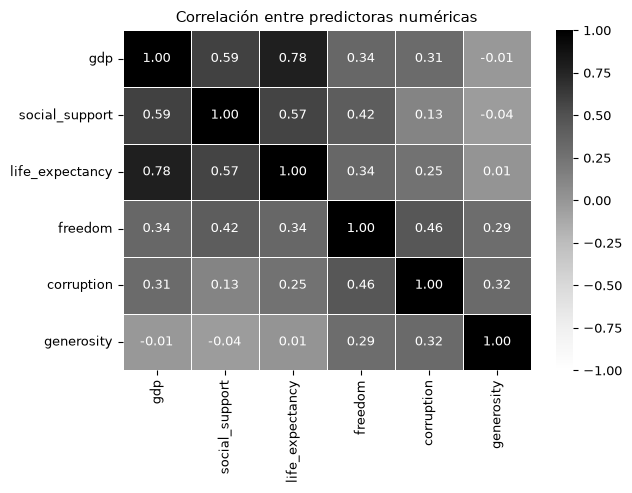

Pares de predictoras más correlacionados (valor absoluto):
gdp             life_expectancy    0.784
                social_support     0.586
social_support  life_expectancy    0.573
freedom         corruption         0.460


In [3]:
TARGET = "score"
NUM = ["gdp", "social_support", "life_expectancy", "freedom", "corruption", "generosity"]
CAT_REGION = ["region"]
CAT_YEAR = ["year"]
FEATURES = NUM + CAT_REGION + CAT_YEAR
GROUP = "country"

print("Objetivo:", TARGET)
print("Predictoras:", FEATURES)
print("Excluidas: rank (fuga de datos), country (identificador)")

corr_pred = df[NUM].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_pred, annot=True, fmt=".2f", cmap="Greys", vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", ax=ax)
ax.set_title("Correlación entre predictoras numéricas")
ax.grid(False)
plt.tight_layout()
plt.show()

pares = corr_pred.abs().where(np.triu(np.ones(corr_pred.shape), 1).astype(bool)).stack()
print("Pares de predictoras más correlacionados (valor absoluto):")
print(pares.sort_values(ascending=False).head(4).round(3).to_string())

## 3. Partición entrenamiento / prueba por país

En el EDA se observó que la desviación del score dentro de un mismo país es mucho menor que la desviación total: un país tiene casi el mismo puntaje todos los años. Una partición aleatoria por filas dejaría al mismo país en entrenamiento y en prueba, y el modelo evaluaría con observaciones casi idénticas a las vistas, inflando las métricas.

Se usa `GroupShuffleSplit` con `country` como grupo (80 % / 20 %). Así, la prueba mide la capacidad de predecir **países no vistos**. La semilla es fija para reproducir el resultado.

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_train, idx_test = next(gss.split(df, groups=df[GROUP]))
train = df.iloc[idx_train].reset_index(drop=True)
test = df.iloc[idx_test].reset_index(drop=True)

X_train, y_train, g_train = train[FEATURES], train[TARGET], train[GROUP]
X_test, y_test = test[FEATURES], test[TARGET]

solapados = set(train[GROUP]) & set(test[GROUP])
print("Filas  train / test:", len(train), "/", len(test), f"({len(test)/len(df):.1%} en prueba)")
print("Países train / test:", train[GROUP].nunique(), "/", test[GROUP].nunique())
print("Países en ambos conjuntos:", len(solapados))
assert len(solapados) == 0 and len(train) + len(test) == len(df)

resumen_split = pd.DataFrame({
    "train": y_train.describe(), "test": y_test.describe()}).round(3)
display(resumen_split)

dist_anio = pd.concat({"train": train["year"].value_counts().sort_index(),
                       "test": test["year"].value_counts().sort_index()}, axis=1)
display(dist_anio)

reg_split = pd.concat({"train": train["region"].value_counts(), "test": test["region"].value_counts()},
                      axis=1).fillna(0).astype(int)
display(reg_split)

registrar("9. Conjunto de entrenamiento (por país)", len(train), len(FEATURES) + 1,
          train[GROUP].nunique(), "GroupShuffleSplit, semilla %d" % SEED)
registrar("10. Conjunto de prueba (por país)", len(test), len(FEATURES) + 1,
          test[GROUP].nunique(), "países no vistos en entrenamiento")

Filas  train / test: 626 / 156 (19.9% en prueba)
Países train / test: 131 / 33
Países en ambos conjuntos: 0


,train,test
count,626.000,156.000
mean,5.369,5.420
std,1.097,1.245
min,2.693,2.853
25%,4.514,4.353
50%,5.334,5.266
75%,6.104,6.407
max,7.769,7.561


,train,test
year,,
2015,126,32
2016,125,32
2017,125,30
2018,126,30
2019,124,32


,train,test
region,,
Sub-Saharan Africa,145,51
Central and Eastern Europe,135,10
Latin America and Caribbean,86,25
Middle East and Northern Africa,81,15
Western Europe,75,30
Southern Asia,30,5
Southeastern Asia,29,15
Eastern Asia,25,5
Australia and New Zealand,10,0


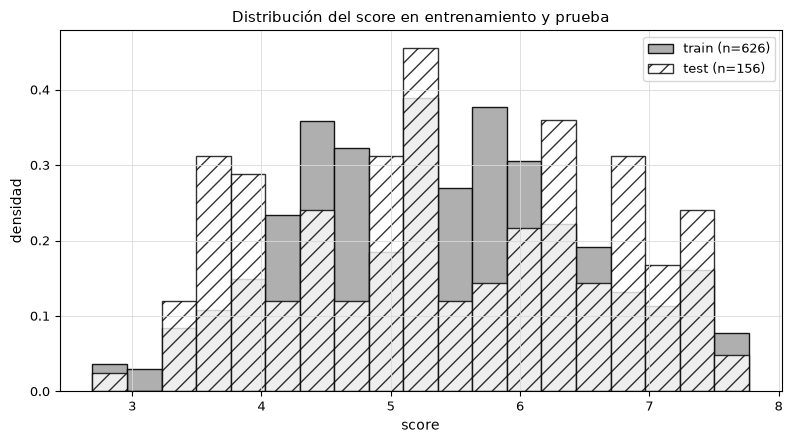

In [5]:
# Gráfica 7: distribución del objetivo en train y test
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(df[TARGET].min(), df[TARGET].max(), 20)
ax.hist(y_train, bins=bins, color="0.65", edgecolor="black", alpha=.9, label=f"train (n={len(y_train)})", density=True)
ax.hist(y_test, bins=bins, color="white", edgecolor="black", hatch="//", alpha=.8, label=f"test (n={len(y_test)})", density=True)
ax.set_xlabel("score")
ax.set_ylabel("densidad")
ax.set_title("Distribución del score en entrenamiento y prueba")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/07_split_distribucion.png", dpi=150)
plt.show()

## 4. Preprocesamiento sin fuga de información

Todo el preprocesamiento vive dentro de un `Pipeline` de scikit-learn. Los parámetros (medianas, medias, desviaciones, categorías) se calculan con `fit` solo sobre los datos de entrenamiento, y en prueba y en validación cruzada solo se aplica `transform`. En validación cruzada, el pipeline completo se reajusta en cada pliegue.

| Columnas | Transformación | Motivo |
|---|---|---|
| Numéricas | Imputación por mediana + estandarización | Maneja el nulo de `corruption`; la estandarización es necesaria para modelos lineales regularizados y hace comparables los coeficientes |
| `region` | Imputación constante + one-hot | Una región nula pasa a una categoría propia; `handle_unknown="ignore"` permite regiones nuevas en streaming |
| `year` | One-hot | Efecto de desplazamiento por año |

In [6]:
def crear_preprocesador(num=NUM, region=CAT_REGION, year=CAT_YEAR):
    pasos = []
    if num:
        pasos.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("scaler", StandardScaler())]), list(num)))
    if region:
        pasos.append(("region", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="desconocida")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]), list(region)))
    if year:
        pasos.append(("year", OneHotEncoder(handle_unknown="ignore"), list(year)))
    return ColumnTransformer(pasos)

# Demostración del ajuste solo con train
prep_demo = crear_preprocesador()
Xt_train = prep_demo.fit_transform(X_train)
Xt_test = prep_demo.transform(X_test)
print("Train transformado:", Xt_train.shape, "| Test transformado:", Xt_test.shape)
print("Nulos tras transformar (train, test):", int(np.isnan(Xt_train).sum()), int(np.isnan(Xt_test).sum()))

medianas = pd.Series(prep_demo.named_transformers_["num"].named_steps["imputer"].statistics_, index=NUM)
print("\nMedianas usadas para imputar (calculadas solo con train):")
print(medianas.round(4).to_string())
print("\nNulos en predictoras: train =", int(X_train.isna().sum().sum()), "| test =", int(X_test.isna().sum().sum()))

Train transformado: (626, 21) | Test transformado: (156, 21)
Nulos tras transformar (train, test): 0 0

Medianas usadas para imputar (calculadas solo con train):
gdp                0.9827
social_support     1.1086
life_expectancy    0.6526
freedom            0.4181
corruption         0.0880
generosity         0.2000

Nulos en predictoras: train = 1 | test = 0


## 5. Selección de características

Se justifica la selección con validación cruzada por grupos (`GroupKFold`, 5 pliegues, agrupando por país) sobre el conjunto de entrenamiento y una regresión lineal como modelo de referencia (rápido e interpretable). Se mide el RMSE de validación cruzada:

1. **Ablación por bloques**: solo numéricas, numéricas + year, numéricas + region, todas.
2. **Eliminación de una variable numérica a la vez**: un aumento del RMSE al quitar una variable indica que aporta información.

El conjunto de prueba no se usa en esta etapa.

In [7]:
cv = GroupKFold(n_splits=5)

def rmse_cv(num, region, year, modelo=None):
    modelo = modelo if modelo is not None else LinearRegression()
    pipe = Pipeline([("prep", crear_preprocesador(num, region, year)), ("model", clone(modelo))])
    r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv,
                       scoring="neg_root_mean_squared_error")
    s = -r["test_score"]
    return s.mean(), s.std()

bloques = {
    "solo numericas": (NUM, [], []),
    "numericas + year": (NUM, [], CAT_YEAR),
    "numericas + region": (NUM, CAT_REGION, []),
    "numericas + region + year": (NUM, CAT_REGION, CAT_YEAR),
}
abl = pd.DataFrame({k: rmse_cv(*v) for k, v in bloques.items()}, index=["rmse_cv_media", "rmse_cv_std"]).T.round(4)
print("Ablación por bloques (regresión lineal, CV por país):")
display(abl)

base_rmse = rmse_cv(NUM, CAT_REGION, CAT_YEAR)[0]
drop = {}
for v in NUM:
    resto = [c for c in NUM if c != v]
    drop[v] = rmse_cv(resto, CAT_REGION, CAT_YEAR)[0]
drop = pd.DataFrame({"rmse_sin_la_variable": drop})
drop["aumento_rmse"] = drop["rmse_sin_la_variable"] - base_rmse
print("\nRMSE con todas las variables: %.4f" % base_rmse)
print("Eliminación de una variable numérica a la vez:")
display(drop.sort_values("aumento_rmse", ascending=False).round(4))

Ablación por bloques (regresión lineal, CV por país):


,rmse_cv_media,rmse_cv_std
solo numericas,0.5633,0.0900
numericas + year,0.5337,0.0842
numericas + region,0.5592,0.0389
numericas + region + year,0.5483,0.0372



RMSE con todas las variables: 0.5483
Eliminación de una variable numérica a la vez:


,rmse_sin_la_variable,aumento_rmse
gdp,0.5864,0.0381
social_support,0.5743,0.0260
freedom,0.5580,0.0097
life_expectancy,0.5472,-0.0011
generosity,0.5456,-0.0026
corruption,0.5377,-0.0106


Criterio de decisión: una variable o bloque se conserva si no empeora el RMSE de validación cruzada. Una variable débil en correlación simple (por ejemplo `generosity`) puede aportar al combinarse con otras, por eso se evalúa su efecto sobre el error y no solo su correlación con `score`. Las decisiones finales se toman con las tablas anteriores; el notebook mantiene el conjunto completo de predictoras salvo que la ablación indique lo contrario, y en ese caso se modifica la lista `FEATURES` de la sección 2 y se reejecuta.

## 6. Comparación de modelos

| Modelo | Papel |
|---|---|
| Referencia (media) | Piso de comparación: predice siempre la media del entrenamiento |
| Regresión lineal | Modelo base solicitado; interpretable |
| Ridge | Lineal con regularización L2; útil si hay colinealidad entre predictoras |
| Random Forest | No lineal; captura interacciones sin supuestos de forma funcional |
| Gradient Boosting | No lineal; suele rendir bien en datos tabulares pequeños |

La selección se hace por el **RMSE medio de validación cruzada por país en entrenamiento**, no por el conjunto de prueba. Así, la prueba se usa una sola vez, para reportar el desempeño del modelo ya elegido.

In [8]:
modelos = {
    "Referencia (media)": DummyRegressor(strategy="mean"),
    "Regresion lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                            random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                    subsample=0.8, random_state=SEED),
}
pipes = {n: Pipeline([("prep", crear_preprocesador()), ("model", m)]) for n, m in modelos.items()}

scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
filas = []
for nombre, pipe in pipes.items():
    r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv, scoring=scoring)
    filas.append({
        "modelo": nombre,
        "mae_cv": -r["test_mae"].mean(), "rmse_cv": -r["test_rmse"].mean(),
        "rmse_cv_std": r["test_rmse"].std(), "r2_cv": r["test_r2"].mean(),
    })
cv_tabla = pd.DataFrame(filas).set_index("modelo").round(4)
display(cv_tabla.sort_values("rmse_cv"))

candidatos = cv_tabla.drop(index="Referencia (media)")
mejor_nombre = candidatos["rmse_cv"].idxmin()
print("Modelo seleccionado por menor RMSE de validación cruzada:", mejor_nombre)

,mae_cv,rmse_cv,rmse_cv_std,r2_cv
modelo,,,,
Ridge,0.4221,0.5453,0.0384,0.7413
Regresion lineal,0.4238,0.5483,0.0372,0.7386
Random Forest,0.4358,0.5597,0.0513,0.7309
Gradient Boosting,0.4347,0.5618,0.0518,0.7290
Referencia (media),0.9109,1.0996,0.0640,-0.0275


Modelo seleccionado por menor RMSE de validación cruzada: Ridge


## 7. Evaluación en el conjunto de prueba

Se reajusta cada modelo sobre todo el entrenamiento y se evalúa **una sola vez** en prueba (países no vistos). Métricas:

- **MAE**: error absoluto medio, en puntos de score.
- **MSE**: error cuadrático medio; penaliza más los errores grandes.
- **RMSE**: raíz del MSE, en las mismas unidades del score.
- **R2**: proporción de la varianza del score explicada por el modelo.
- **R2 ajustado**: R2 penalizado por el número de variables del modelo, `1 - (1 - R2)(n - 1)/(n - p - 1)`. Aquí `p` es el número de columnas tras el preprocesamiento (0 para la referencia).

In [9]:
def metricas(y_true, y_pred, p):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2, "R2_ajustado": r2_adj}

def n_variables(pipe):
    if isinstance(pipe.named_steps["model"], DummyRegressor):
        return 0
    return len(pipe.named_steps["prep"].get_feature_names_out())

ajustados, filas_test, filas_train = {}, [], []
for nombre, pipe in pipes.items():
    p = clone(pipe).fit(X_train, y_train)
    ajustados[nombre] = p
    k = n_variables(p)
    filas_test.append({"modelo": nombre, "p": k, **metricas(y_test, p.predict(X_test), k)})
    filas_train.append({"modelo": nombre, **metricas(y_train, p.predict(X_train), k)})

res_test = pd.DataFrame(filas_test).set_index("modelo")
res_train = pd.DataFrame(filas_train).set_index("modelo")

print("Métricas en PRUEBA (países no vistos):")
display(res_test.round(4))
print("Métricas en ENTRENAMIENTO (para detectar sobreajuste):")
display(res_train.round(4))

brecha = pd.DataFrame({"RMSE_train": res_train["RMSE"], "RMSE_cv": cv_tabla["rmse_cv"],
                       "RMSE_test": res_test["RMSE"]}).round(4)
print("Comparación de RMSE (train, validación cruzada, prueba):")
display(brecha)

Métricas en PRUEBA (países no vistos):


,p,MAE,MSE,RMSE,R2,R2_ajustado
modelo,,,,,,
Referencia (media),0,1.0619,1.5422,1.2419,-0.0017,-0.0017
Regresion lineal,21,0.3592,0.2592,0.5091,0.8316,0.8053
Ridge,21,0.3603,0.2593,0.5093,0.8315,0.8051
Random Forest,21,0.4433,0.3378,0.5812,0.7806,0.7462
Gradient Boosting,21,0.4203,0.2999,0.5476,0.8052,0.7747


Métricas en ENTRENAMIENTO (para detectar sobreajuste):


,MAE,MSE,RMSE,R2,R2_ajustado
modelo,,,,,
Referencia (media),0.9075,1.2017,1.0962,0.0000,0.0000
Regresion lineal,0.3600,0.2135,0.4621,0.8223,0.8162
Ridge,0.3603,0.2136,0.4622,0.8222,0.8161
Random Forest,0.1382,0.0366,0.1913,0.9695,0.9685
Gradient Boosting,0.1713,0.0470,0.2169,0.9609,0.9595


Comparación de RMSE (train, validación cruzada, prueba):


,RMSE_train,RMSE_cv,RMSE_test
modelo,,,
Referencia (media),1.0962,1.0996,1.2419
Regresion lineal,0.4621,0.5483,0.5091
Ridge,0.4622,0.5453,0.5093
Random Forest,0.1913,0.5597,0.5812
Gradient Boosting,0.2169,0.5618,0.5476


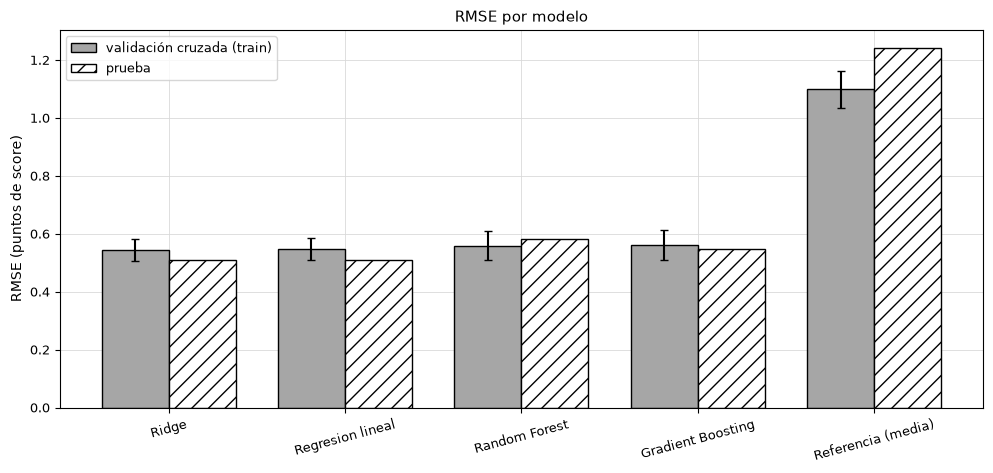

In [10]:
# Gráfica 8: comparación de modelos (RMSE en validación cruzada y en prueba)
orden = brecha.drop(index="Referencia (media)").sort_values("RMSE_cv").index.tolist() + ["Referencia (media)"]
x = np.arange(len(orden))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.set_axisbelow(True)
ax.bar(x - w/2, brecha.loc[orden, "RMSE_cv"], w, color="0.65", edgecolor="black", label="validación cruzada (train)")
ax.bar(x + w/2, brecha.loc[orden, "RMSE_test"], w, color="white", edgecolor="black", hatch="//", label="prueba")
ax.errorbar(x - w/2, brecha.loc[orden, "RMSE_cv"], yerr=cv_tabla.loc[orden, "rmse_cv_std"],
            fmt="none", ecolor="black", capsize=3)
ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15)
ax.set_ylabel("RMSE (puntos de score)")
ax.set_title("RMSE por modelo")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/08_comparacion_modelos.png", dpi=150)
plt.show()

### Modelo seleccionado: diagnóstico detallado
Se analiza el modelo elegido por validación cruzada: comparación de predicciones con valores reales, residuos y errores por grupo.

In [11]:
pipe_final = ajustados[mejor_nombre]
pred_test = pipe_final.predict(X_test)
k_final = n_variables(pipe_final)
m_final = metricas(y_test, pred_test, k_final)

print("Modelo:", mejor_nombre)
print(pd.Series(m_final).round(4).to_string())

resultados = test[["year", "country", "region", TARGET]].copy()
resultados["pred"] = pred_test
resultados["error"] = resultados["pred"] - resultados[TARGET]
resultados["error_abs"] = resultados["error"].abs()
resultados.to_csv(f"{DIR_TAB}/predicciones_test.csv", index=False)

print("\nPrimeras comparaciones predicho vs real:")
display(resultados.head(10).round(3))

registrar("11. Predicciones evaluadas en prueba", len(resultados), None, resultados["country"].nunique(),
          "modelo: %s" % mejor_nombre)

Modelo: Ridge
MAE            0.3603
MSE            0.2593
RMSE           0.5093
R2             0.8315
R2_ajustado    0.8051

Primeras comparaciones predicho vs real:


,year,country,region,score,pred,error,error_abs
0,2015,Belgium,Western Europe,6.937,6.700,-0.237,0.237
1,2015,United Kingdom,Western Europe,6.867,6.948,0.081,0.081
2,2015,Germany,Western Europe,6.750,6.798,0.048,0.048
3,2015,Colombia,Latin America and Caribbean,6.477,6.180,-0.297,0.297
4,2015,Spain,Western Europe,6.329,6.336,0.007,0.007
5,2015,Bahrain,Middle East and Northern Africa,5.960,6.093,0.133,0.133
6,2015,Bolivia,Latin America and Caribbean,5.890,5.752,-0.138,0.138
7,2015,Bhutan,Southern Asia,5.253,5.472,0.219,0.219
8,2015,Montenegro,Central and Eastern Europe,5.192,5.099,-0.093,0.093
9,2015,Latvia,Central and Eastern Europe,5.098,5.486,0.388,0.388


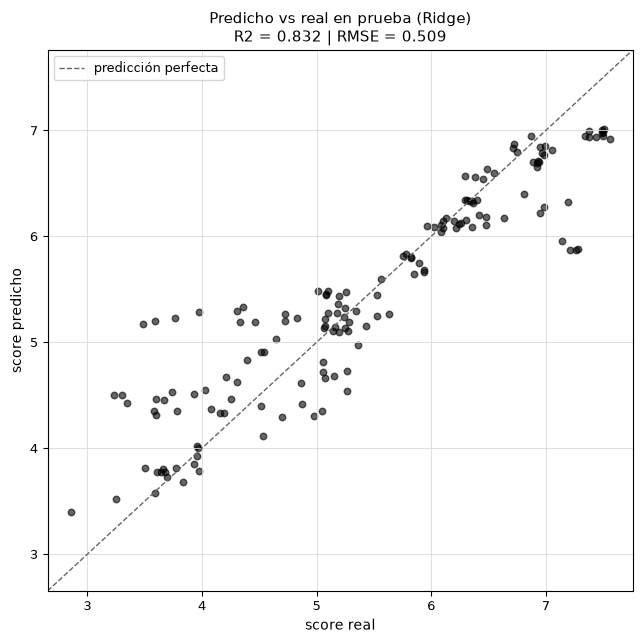

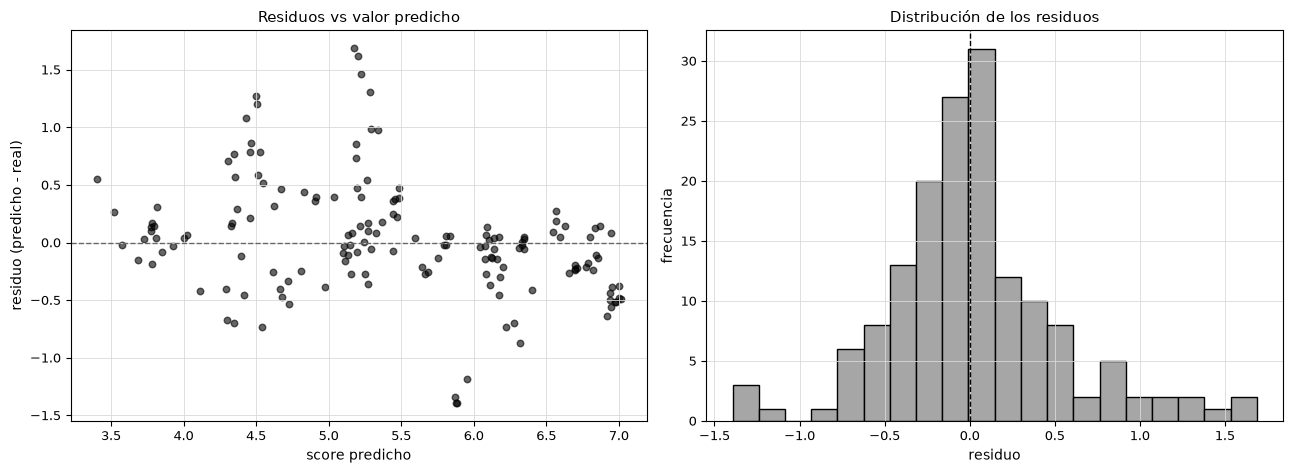

Sesgo medio (media del residuo): 0.0215
Predicciones con error absoluto <= 0.25: 50.6%
Predicciones con error absoluto <= 0.50: 76.3%
Predicciones con error absoluto <= 1.00: 92.9%


In [12]:
# Gráfica 9: predicho vs real
fig, ax = plt.subplots(figsize=(6.5, 6.5))
lim = [min(y_test.min(), pred_test.min()) - 0.2, max(y_test.max(), pred_test.max()) + 0.2]
ax.plot(lim, lim, color="0.4", linestyle="--", linewidth=1, label="predicción perfecta")
ax.scatter(y_test, pred_test, s=22, color="black", alpha=.6)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("score real")
ax.set_ylabel("score predicho")
ax.set_title(f"Predicho vs real en prueba ({mejor_nombre})\nR2 = {m_final['R2']:.3f} | RMSE = {m_final['RMSE']:.3f}")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/09_pred_vs_real.png", dpi=150)
plt.show()

# Gráfica 10: residuos
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(resultados["pred"], resultados["error"], s=22, color="black", alpha=.6)
axes[0].axhline(0, color="0.4", linestyle="--", linewidth=1)
axes[0].set_xlabel("score predicho")
axes[0].set_ylabel("residuo (predicho - real)")
axes[0].set_title("Residuos vs valor predicho")
axes[1].hist(resultados["error"], bins=20, color="0.65", edgecolor="black")
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("residuo")
axes[1].set_ylabel("frecuencia")
axes[1].set_title("Distribución de los residuos")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/10_residuos.png", dpi=150)
plt.show()

print("Sesgo medio (media del residuo): %.4f" % resultados["error"].mean())
print("Predicciones con error absoluto <= 0.25: %.1f%%" % (100 * (resultados["error_abs"] <= 0.25).mean()))
print("Predicciones con error absoluto <= 0.50: %.1f%%" % (100 * (resultados["error_abs"] <= 0.50).mean()))
print("Predicciones con error absoluto <= 1.00: %.1f%%" % (100 * (resultados["error_abs"] <= 1.00).mean()))

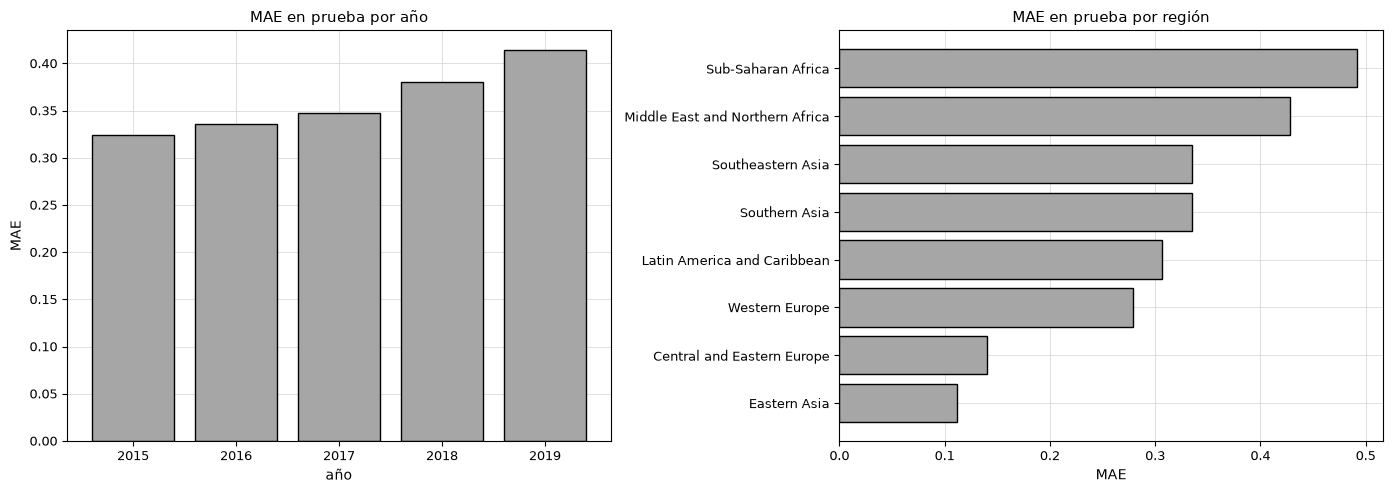

Error por año:


,MAE,count
year,,
2015,0.324,32
2016,0.336,32
2017,0.347,30
2018,0.380,30
2019,0.414,32


Error por región:


,MAE,count
region,,
Eastern Asia,0.112,5
Central and Eastern Europe,0.140,10
Western Europe,0.279,30
Latin America and Caribbean,0.306,25
Southern Asia,0.335,5
Southeastern Asia,0.335,15
Middle East and Northern Africa,0.428,15
Sub-Saharan Africa,0.492,51


MAE en filas con algún cero exacto en predictoras: 0.461 (n=1)
MAE en el resto: 0.360 (n=155)

Las 10 predicciones con mayor error absoluto:


,year,country,region,score,pred,error,error_abs
155,2019,Botswana,Sub-Saharan Africa,3.488,5.175,1.687,1.687
113,2018,Botswana,Sub-Saharan Africa,3.590,5.205,1.615,1.615
76,2017,Botswana,Sub-Saharan Africa,3.766,5.226,1.460,1.460
26,2015,Israel,Middle East and Northern Africa,7.278,5.884,-1.394,1.394
32,2016,Israel,Middle East and Northern Africa,7.267,5.875,-1.392,1.392
80,2017,Israel,Middle East and Northern Africa,7.213,5.872,-1.341,1.341
40,2016,Botswana,Sub-Saharan Africa,3.974,5.283,1.309,1.309
135,2019,Tanzania,Sub-Saharan Africa,3.231,4.502,1.271,1.271
106,2018,Tanzania,Sub-Saharan Africa,3.303,4.505,1.202,1.202
124,2019,Israel,Middle East and Northern Africa,7.139,5.956,-1.183,1.183


In [13]:
# Error por año y por región; filas con ceros en predictoras
por_anio = resultados.groupby("year")["error_abs"].agg(["mean", "count"]).rename(columns={"mean": "MAE"})
por_region = resultados.groupby("region")["error_abs"].agg(["mean", "count"]).rename(columns={"mean": "MAE"}).sort_values("MAE")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].set_axisbelow(True)
axes[0].bar(por_anio.index.astype(str), por_anio["MAE"], color="0.65", edgecolor="black")
axes[0].set_title("MAE en prueba por año")
axes[0].set_xlabel("año"); axes[0].set_ylabel("MAE")
axes[1].set_axisbelow(True)
axes[1].barh(por_region.index, por_region["MAE"], color="0.65", edgecolor="black")
axes[1].set_title("MAE en prueba por región")
axes[1].set_xlabel("MAE")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/11_error_por_grupo.png", dpi=150)
plt.show()

print("Error por año:"); display(por_anio.round(3))
print("Error por región:"); display(por_region.round(3))

tiene_cero = (test[NUM] == 0).any(axis=1).values
if tiene_cero.any():
    print("MAE en filas con algún cero exacto en predictoras: %.3f (n=%d)" % (resultados.loc[tiene_cero, "error_abs"].mean(), tiene_cero.sum()))
    print("MAE en el resto: %.3f (n=%d)" % (resultados.loc[~tiene_cero, "error_abs"].mean(), (~tiene_cero).sum()))

print("\nLas 10 predicciones con mayor error absoluto:")
display(resultados.sort_values("error_abs", ascending=False).head(10).round(3))

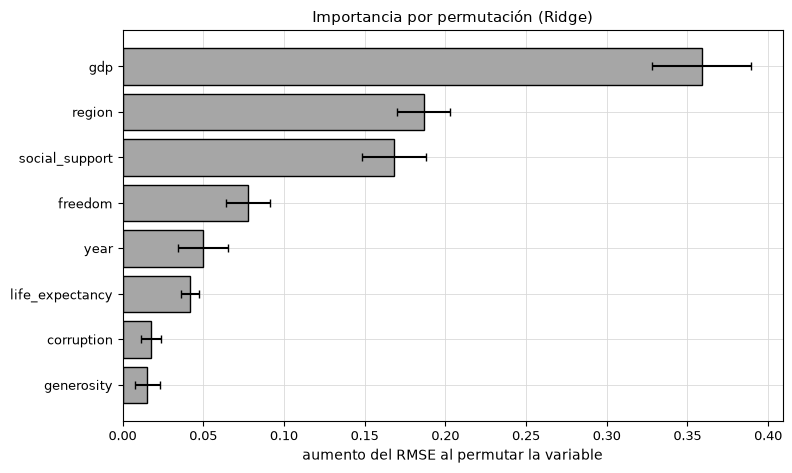

,importancia,std
gdp,0.3589,0.0306
region,0.1865,0.0164
social_support,0.1680,0.0199
freedom,0.0779,0.0137
year,0.0498,0.0154
life_expectancy,0.0419,0.0058
corruption,0.0177,0.0062
generosity,0.0153,0.0077


Regresión lineal: coeficientes de las variables numéricas (por 1 desviación estándar):
num__gdp                0.4202
num__social_support     0.2977
num__freedom            0.1848
num__corruption         0.1024
num__generosity         0.0689
num__life_expectancy    0.0633


In [14]:
# Gráfica 12: importancia de variables por permutación (en prueba, sobre las variables originales)
perm = permutation_importance(pipe_final, X_test, y_test, n_repeats=30, random_state=SEED,
                              scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"importancia": perm.importances_mean, "std": perm.importances_std},
                   index=FEATURES).sort_values("importancia")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.set_axisbelow(True)
ax.barh(imp.index, imp["importancia"], xerr=imp["std"], color="0.65", edgecolor="black", ecolor="black", capsize=3)
ax.set_xlabel("aumento del RMSE al permutar la variable")
ax.set_title(f"Importancia por permutación ({mejor_nombre})")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/12_importancia_variables.png", dpi=150)
plt.show()
display(imp.sort_values("importancia", ascending=False).round(4))

# Coeficientes del modelo lineal (variables estandarizadas): interpretación directa
lin = ajustados["Regresion lineal"]
nombres = lin.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lin.named_steps["model"].coef_, index=nombres)
print("Regresión lineal: coeficientes de las variables numéricas (por 1 desviación estándar):")
print(coef[[n for n in nombres if n.startswith("num__")]].sort_values(ascending=False).round(4).to_string())

## 8. Persistencia del modelo

Se guarda el pipeline completo (preprocesamiento + modelo) junto con los metadatos que necesita el consumidor de streaming:

- `features`: columnas y orden esperados como entrada.
- `region_map`: país -> región, porque los archivos de 2017-2019 no traen `region` y el consumidor debe recuperarla igual que en el EDA.
- `metricas_test`: métricas del modelo guardado.

El modelo guardado es el entrenado **solo con el conjunto de entrenamiento**, para que las métricas reportadas correspondan exactamente al artefacto. Reentrenar con todos los datos es posible, pero las métricas de prueba dejarían de ser comparables.

In [15]:
region_map = df.dropna(subset=["region"]).drop_duplicates("country").set_index("country")["region"].to_dict()

artefacto = {
    "pipeline": pipe_final,
    "modelo": mejor_nombre,
    "target": TARGET,
    "features": FEATURES,
    "num": NUM, "cat_region": CAT_REGION, "cat_year": CAT_YEAR,
    "region_map": region_map,
    "metricas_test": {k: float(v) for k, v in m_final.items()},
    "semilla": SEED,
    "sklearn": sklearn.__version__,
    "entrenado_en": datetime.datetime.now().isoformat(timespec="seconds"),
}
joblib.dump(artefacto, f"{DIR_MOD}/model.joblib")
with open(f"{DIR_MOD}/metrics.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": mejor_nombre, "metricas_test": artefacto["metricas_test"],
               "cv": cv_tabla.loc[mejor_nombre].to_dict(), "n_train": len(train), "n_test": len(test)}, f, indent=2)

# Tablas de apoyo
pd.concat({"cv_train": cv_tabla, "test": res_test}, axis=1).to_csv(f"{DIR_TAB}/comparacion_modelos.csv")

# Verificación: recargar y predecir igual
cargado = joblib.load(f"{DIR_MOD}/model.joblib")
assert np.allclose(cargado["pipeline"].predict(X_test), pred_test)

# Prueba con un registro con el formato que producirá el consumidor de streaming
ejemplo = pd.DataFrame([{"gdp": 1.2, "social_support": 1.1, "life_expectancy": 0.8, "freedom": 0.4,
                         "corruption": np.nan, "generosity": 0.2, "region": "Western Europe", "year": 2019}])[FEATURES]
print("Modelo guardado y verificado:", f"{DIR_MOD}/model.joblib")
print("Predicción de ejemplo (corruption nulo, se imputa):", float(cargado["pipeline"].predict(ejemplo)[0]))

Modelo guardado y verificado: ../models/model.joblib
Predicción de ejemplo (corruption nulo, se imputa): 5.90277899997796


,etapa,filas,columnas,paises_unicos,nota
0,1. Mensajes disponibles en el tópico,782,NaN,NaN,consulta en vivo a Kafka
1,2. Mensajes consumidos y almacenados,782,35.0,170.0,raw_records.csv (incluye 5 columnas de metadatos)
2,1. Mensajes disponibles en el tópico,782,NaN,NaN,consulta en vivo a Kafka
3,2. Mensajes consumidos y almacenados,782,35.0,170.0,raw_records.csv (incluye 5 columnas de metadatos)
4,3. Sin duplicados por record_id,782,35.0,170.0,duplicados detectados: 0
5,4. Esquema unificado (formato largo),782,11.0,170.0,10 columnas comunes + year; 7 columnas origina...
6,5. Nombres de país unificados,782,11.0,164.0,12 filas renombradas
7,6. Unicidad país-año verificada,782,11.0,164.0,0 duplicados eliminados
8,7. Objetivo (score) válido,782,11.0,164.0,0 filas sin score
9,8. Dataset limpio (entrada de modelado),782,11.0,164.0,"781 filas completas, 1 con nulo pendiente de i..."


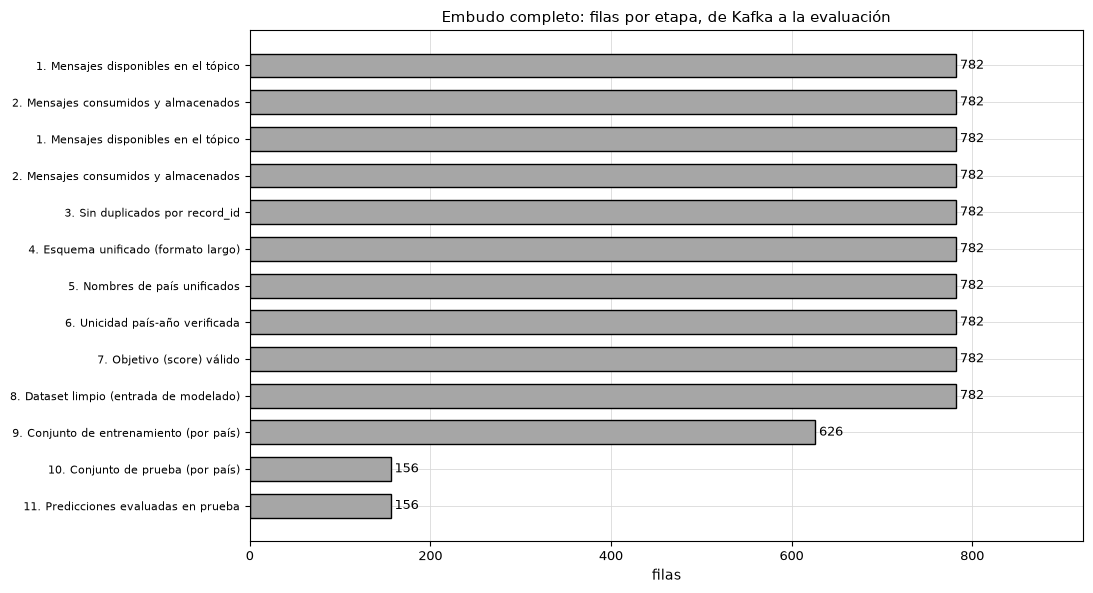

In [16]:
# Embudo completo: desde los mensajes de Kafka hasta las predicciones evaluadas
tabla_embudo = pd.DataFrame(embudo)
display(tabla_embudo)
tabla_embudo.to_csv(f"{DIR_TAB}/embudo_completo.csv", index=False)

def barras(ax, etiquetas, valores, titulo, xlabel):
    y = np.arange(len(etiquetas))[::-1]
    ax.set_axisbelow(True)
    ax.barh(y, valores, color="0.65", edgecolor="black", height=0.65)
    for yi, v in zip(y, valores):
        ax.text(v, yi, f" {int(v)}", va="center", fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlim(0, max(valores) * 1.18)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)

fig, ax = plt.subplots(figsize=(11, 6))
barras(ax, tabla_embudo["etapa"].tolist(), tabla_embudo["filas"].tolist(),
       "Embudo completo: filas por etapa, de Kafka a la evaluación", "filas")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/13_embudo_completo.png", dpi=150)
plt.show()

## 9. Discusión

La siguiente celda redacta la lectura de las métricas a partir de los valores calculados.

In [17]:
rmse_ref = res_test.loc["Referencia (media)", "RMSE"]
mejora = 100 * (1 - m_final["RMSE"] / rmse_ref)
sd_test = y_test.std()

print("LECTURA DE RESULTADOS")
print("-" * 70)
print(f"Modelo seleccionado (menor RMSE en validación cruzada por país): {mejor_nombre}.")
print(f"1. R2 = {m_final['R2']:.3f} (ajustado {m_final['R2_ajustado']:.3f}): el modelo explica "
      f"{100*m_final['R2']:.1f}% de la varianza del score en países no vistos.")
print(f"2. MAE = {m_final['MAE']:.3f} y RMSE = {m_final['RMSE']:.3f} puntos de score; "
      f"la desviación estándar del score en prueba es {sd_test:.3f}.")
print(f"3. Frente a predecir siempre la media (RMSE {rmse_ref:.3f}), el RMSE baja {mejora:.1f}%.")
print(f"4. RMSE mayor que MAE en un factor {m_final['RMSE']/m_final['MAE']:.2f}: "
      f"{'hay algunos errores grandes que pesan más en el RMSE' if m_final['RMSE']/m_final['MAE'] > 1.3 else 'los errores son relativamente homogéneos'}.")
print(f"5. Sesgo medio del residuo: {resultados['error'].mean():+.3f} "
      f"({'predice por encima' if resultados['error'].mean() > 0 else 'predice por debajo'} del valor real en promedio).")
print(f"6. Brecha de RMSE entre entrenamiento y prueba: {brecha.loc[mejor_nombre, 'RMSE_train']:.3f} vs "
      f"{brecha.loc[mejor_nombre, 'RMSE_test']:.3f}; entre validación cruzada y prueba: "
      f"{brecha.loc[mejor_nombre, 'RMSE_cv']:.3f} vs {brecha.loc[mejor_nombre, 'RMSE_test']:.3f}.")
print(f"7. Variable con mayor importancia por permutación: {imp.index[-1]}; "
      f"la de menor importancia: {imp.index[0]}.")
mejor_lin = res_test.loc["Regresion lineal", "RMSE"]
print(f"8. Regresión lineal en prueba: RMSE {mejor_lin:.3f} y R2 {res_test.loc['Regresion lineal', 'R2']:.3f}.")

LECTURA DE RESULTADOS
----------------------------------------------------------------------
Modelo seleccionado (menor RMSE en validación cruzada por país): Ridge.
1. R2 = 0.832 (ajustado 0.805): el modelo explica 83.2% de la varianza del score en países no vistos.
2. MAE = 0.360 y RMSE = 0.509 puntos de score; la desviación estándar del score en prueba es 1.245.
3. Frente a predecir siempre la media (RMSE 1.242), el RMSE baja 59.0%.
4. RMSE mayor que MAE en un factor 1.41: hay algunos errores grandes que pesan más en el RMSE.
5. Sesgo medio del residuo: +0.022 (predice por encima del valor real en promedio).
6. Brecha de RMSE entre entrenamiento y prueba: 0.462 vs 0.509; entre validación cruzada y prueba: 0.545 vs 0.509.
7. Variable con mayor importancia por permutación: gdp; la de menor importancia: generosity.
8. Regresión lineal en prueba: RMSE 0.509 y R2 0.832.


### Interpretación de las métricas

- Un R2 cercano a 1 indica que las predictoras explican gran parte de la variación del score; el R2 ajustado lo corrige por el número de columnas del modelo y es el más adecuado para comparar modelos con distinta cantidad de variables.
- MAE y RMSE están en puntos de score (escala aproximada de 2.5 a 8), por lo que se interpretan directamente como error típico de la predicción.
- La comparación entre el RMSE de entrenamiento, de validación cruzada y de prueba indica si hay sobreajuste: una brecha grande entre entrenamiento y prueba lo sugiere.
- Como la partición es por país, las métricas de prueba miden generalización a países no vistos, no la repetición de países ya conocidos.

### Limitaciones de la evaluación

- Con 782 filas y cerca de 170 países, el conjunto de prueba contiene pocos países (alrededor de 34). Las métricas dependen de la partición elegida; la desviación estándar entre pliegues de validación cruzada da una idea de esa variabilidad.
- Las predictoras (`gdp`, `social_support`, `life_expectancy`, `freedom`, `corruption`, `generosity`) son componentes que el informe usa para explicar el score. Esta relación casi aritmética hace que el problema sea más fácil que predecir la felicidad a partir de variables externas.
- `social_support` cambia de nivel entre 2016 y 2017 y `life_expectancy` en 2019 (ver 01_eda). `year` como variable categórica absorbe parte del desplazamiento, pero no corrige diferencias que afecten a unos países más que a otros.
- Los ceros exactos en las predictoras no están confirmados como datos reales; si son datos faltantes codificados, introducen ruido en el entrenamiento y en la evaluación.
- No hay ajuste de hiperparámetros: los modelos usan configuraciones razonables fijas.

### Posibles mejoras

1. Ajustar hiperparámetros con `GridSearchCV` o `RandomizedSearchCV` usando `GroupKFold`.
2. Validar los ceros con la documentación oficial y, si son faltantes, tratarlos como nulos e imputarlos.
3. Normalizar cada predictora por año (por ejemplo, z-score dentro de cada año) para neutralizar los cambios de escala.
4. Evaluar con una partición temporal adicional (entrenar con 2015-2018 y probar con 2019) para medir la estabilidad en el tiempo.
5. Probar transformaciones de las variables sesgadas (`corruption`, `generosity`) o términos de interacción en el modelo lineal.
6. Repetir la partición por país con varias semillas (`GroupShuffleSplit` con `n_splits` mayor) para reportar un intervalo de las métricas.
7. Reentrenar el modelo final con todos los datos una vez elegida la configuración, para el despliegue en streaming.

### Siguiente paso
El consumidor de streaming debe aplicar a cada mensaje la misma transformación del EDA (mapa de nombres de columna, unificación de nombres de país y recuperación de `region` con `region_map`), construir un DataFrame con las columnas de `features`, predecir con `model.joblib` y cargar el resultado en la base de datos.